超几何分布: 袋中共有 N=10 颗围棋子（其中黑子 M=4 颗，白子 6 颗），每次不放回地一把抓出 n=5 颗，记录其中黑子的个数 X

超几何单次抓球结果: [0 0 1 1 1] -> 黑子个数 X = 3
模拟频率: [0.02347 0.23691 0.47813 0.23836 0.02313]
理论概率: [0.023809523809523808, 0.23809523809523808, 0.47619047619047616, 0.23809523809523808, 0.023809523809523808]
 X (黑子的个数)   |    模拟频率 (N=10万)    |     超几何分布理论概率     
------------------------------------------------------
      0        |       0.02347        |       0.02381       
      1        |       0.23691        |       0.23810       
      2        |       0.47813        |       0.47619       
      3        |       0.23836        |       0.23810       
      4        |       0.02313        |       0.02381       


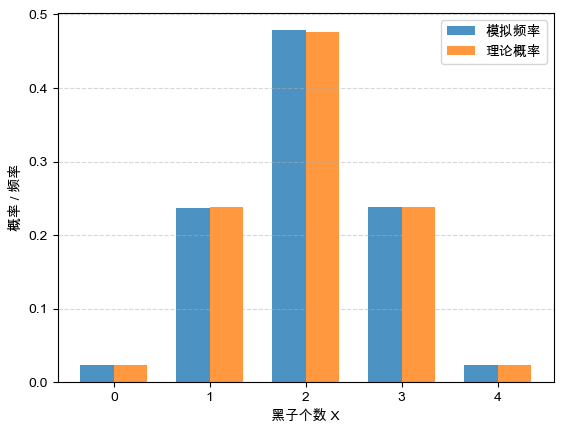

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb  # 用于计算组合数 C(n, k)

# 设置中文字体（防止画图中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ---------------- 场景 1：超几何分布（无放回抓球） ----------------
# 袋中有 4 个黑子(1) 和 6 个白子(0)，共 10 个球
bag = [1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
N = len(bag)
M = 4
n = 5
Ntrials = 100000

# 动作：不放回地 (replace=False) 一把抓出 5 个球 (size=5)
hand = np.random.choice(bag, size=5, replace=False)
print("超几何单次抓球结果:", hand, "-> 黑子个数 X =", np.sum(hand))


# ---------------- 场景 2：完成10000次抓球 ----------------
X_results = [
    np.sum(np.random.choice(bag, size=5, replace=False))
    for _ in range(Ntrials)
]

# ---------------- 统计模拟结果 ----------------
sim_probs = np.bincount(X_results) / Ntrials

# ---------------- 计算理论概率 ----------------
# 理论概率计算
theo_probs = [comb(M, k)*comb(N-M, n-k) / comb(N, n) for k in range(5)]
print("理论概率:", theo_probs)

# ---------------- 打印分布表 （可直接填入实验报告单）----------------
k_values = np.arange(0, 5)
print(f"{'X (黑子的个数)':^12} | {'模拟频率 (N=10万)':^18} | {'超几何分布理论概率':^18}")
print("-" * 54)
for k, sim_p, theo_p in zip(k_values, sim_probs, theo_probs):
  print(f"{k:^14d} | {sim_p:^20.5f} | {theo_p:^20.5f}")



# 5. 绘制模拟和理论对比图

width = 0.35
plt.bar(
    k_values - width / 2, sim_probs, width, label="模拟频率", alpha=0.8
)
plt.bar(
    k_values + width / 2, theo_probs, width, label="理论概率", alpha=0.8
)
plt.xticks(k_values)
plt.xlabel("黑子个数 X")
plt.ylabel("概率 / 频率")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()



二项分布: 每次抛出5个骰子, X代表其中的点数为6的个数


  X (6的个数)   |    模拟频率 (N=10万)    |      二项分布理论概率     
------------------------------------------------------
      0        |       0.40010        |       0.40188       
      1        |       0.40362        |       0.40188       
      2        |       0.16075        |       0.16075       
      3        |       0.03225        |       0.03215       
      4        |       0.00310        |       0.00322       
      5        |       0.00018        |       0.00013       


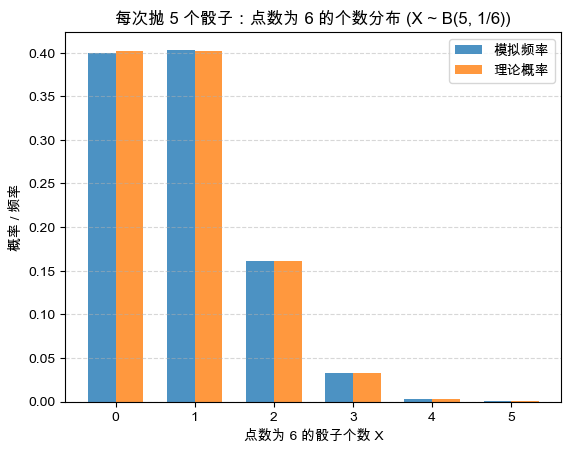

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import comb  # 用于计算组合数 C(n, k)

# 设置中文字体（防止画图中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 1. 实验参数设置
N_trials = 100000  # 模拟总次数：10万次
n = 5  # 每次抛出 5 个骰子
p = 1 / 6  # 单颗骰子点数为 6 的概率
die = [1, 2, 3, 4, 5, 6]

# 2. 进行 100,000 次抛骰子实验
# 生成 100000 行 x 5 列的矩阵，每一行代表一次抛出 5 个骰子的点数
all_rolls = np.random.choice(die, size=(N_trials, n), replace=True)

# 判断哪些位置点数等于 6，并按行求和（axis=1），得到每次实验的 X 值
X_results = np.sum(all_rolls == 6, axis=1)

# 3. 统计模拟频率与计算理论概率
k_values = np.arange(0, n + 1)  # X 的所有可能取值: 0, 1, 2, 3, 4, 5
sim_probs = np.bincount(X_results) / N_trials  # 模拟频率
theo_probs = [
    comb(n, k) * (p**k) * ((1 - p) ** (n - k)) for k in k_values
]  # 二项分布理论公式

# 4. 打印分布表格（可直接填入实验报告单）
print(f"{'X (6的个数)':^12} | {'模拟频率 (N=10万)':^18} | {'二项分布理论概率':^18}")
print("-" * 54)
for k, sim_p, theo_p in zip(k_values, sim_probs, theo_probs):
  print(f"{k:^14d} | {sim_p:^20.5f} | {theo_p:^20.5f}")

# 5. 绘制模拟和理论对比图
width = 0.35
plt.bar(
    k_values - width / 2, sim_probs, width, label="模拟频率", alpha=0.8
)
plt.bar(
    k_values + width / 2, theo_probs, width, label="理论概率", alpha=0.8
)
plt.xticks(k_values)
plt.xlabel("点数为 6 的骰子个数 X")
plt.ylabel("概率 / 频率")
plt.title("每次抛 5 个骰子：点数为 6 的个数分布 (X ~ B(5, 1/6))")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()
